# Analysis of clone-to-clone variation of RMCE and random-integration CHO clones in ambr15 fed-batch cultures

Design: three RMCE clones and three random-integration (RI) clones each producing EPO or etanercept (ETN).
RMCE clones were cultivated in a full-factorial DoE (temperature shift on day 4: 31 or 34 °C; feed: Cell Boost 5 or 7; basal medium: FortiCHO or OptiCHO; pH set point 6.9, 7.1 or 7.3).
RI clones were cultivated in 8 of these conditions.

Hypothesis: RMCE clones behave alike, clone identity should explain little variance and certainly less than RI clones.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

OUT = Path("./analysis_outputs")
OUT.mkdir(parents=True, exist_ok=True)

FACTORS = ["temp_shift", "feed", "medium", "ph"]

FACTOR_LABELS = {"temp_shift": "Temp shift", "feed": "Feed", "medium": "Base medium", "ph": "pH"}
PARAMETER_LABELS = {"AMMONIUM": "Ammonium", "CELL_COUNT": "Cell count", "LACTATE": "Lactate", "titer": "Titer"}
LOGWORTH = r"Logworth ($-\log_{10}p$)"

def label_grid(g, row_labels, xlabel="Culture day"):
    """Parameter name as title on the top row, one y label per row."""
    g.set_titles("{col_name}").set_xlabels(xlabel)
    for ax in g.axes[1:].flat:
        ax.set_title("")
    for axes_row, label in zip(g.axes, row_labels):
        axes_row[0].set_ylabel(label)

sns.set_theme(context='paper', style='whitegrid')

In [2]:
ambr = pd.read_feather("ambr_long.feather").astype({"clone": str, "temp_shift": str, "ph": str})
ambr

,product,integration,clone,run,vid,vessel,condition,temp_shift,feed,medium,ph,parameter,seconds,day,value,note
0,EPO,RI,12,RANDOM_EPO,CS1_5,EPO_12_CS1_5,N3,34,Cell Boost 5,FortiCHO,7.3,AMMONIUM,50400,0.583333,0.940000,
1,EPO,RI,12,RANDOM_EPO,CS1_5,EPO_12_CS1_5,N3,34,Cell Boost 5,FortiCHO,7.3,AMMONIUM,77640,0.898611,1.120000,
2,EPO,RI,12,RANDOM_EPO,CS1_5,EPO_12_CS1_5,N3,34,Cell Boost 5,FortiCHO,7.3,AMMONIUM,147960,1.712500,2.010000,
3,EPO,RI,12,RANDOM_EPO,CS1_5,EPO_12_CS1_5,N3,34,Cell Boost 5,FortiCHO,7.3,AMMONIUM,225060,2.604861,3.440000,
4,EPO,RI,12,RANDOM_EPO,CS1_5,EPO_12_CS1_5,N3,34,Cell Boost 5,FortiCHO,7.3,AMMONIUM,308040,3.565278,5.440000,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31529,ETN,RMCE,B4,B4_ENB,CS2_9,ETN_B4_CS2_9,N21,31,Cell Boost 7,FortiCHO,7.3,titer,864000,10.000000,759.224254,
31530,ETN,RMCE,B4,B4_ENB,CS2_9,ETN_B4_CS2_9,N21,31,Cell Boost 7,FortiCHO,7.3,titer,950400,11.000000,852.778302,
31531,ETN,RMCE,B4,B4_ENB,CS2_9,ETN_B4_CS2_9,N21,31,Cell Boost 7,FortiCHO,7.3,titer,1036800,12.000000,962.323557,
31532,ETN,RMCE,B4,B4_ENB,CS2_9,ETN_B4_CS2_9,N21,31,Cell Boost 7,FortiCHO,7.3,titer,1123200,13.000000,1031.620062,


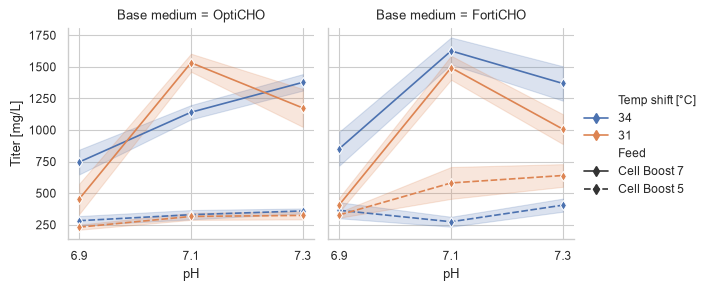

In [3]:
d14 = ambr[(ambr.parameter == "titer") & (ambr.day == 14)]
d14_rmce = d14[d14.integration == "RMCE"].sort_values("ph")

fig1 = sns.relplot(d14_rmce.rename(columns={"value": "Titer [mg/L]", "ph": "pH", "temp_shift": "Temp shift [°C]", "feed": "Feed", "medium": "Base medium"}), kind="line", x="pH", y="Titer [mg/L]", hue="Temp shift [°C]", style="Feed", col="Base medium", errorbar="se", marker="d", height=3)
fig1.savefig(OUT / "fig_rmce_titer_by_condition")
plt.show()

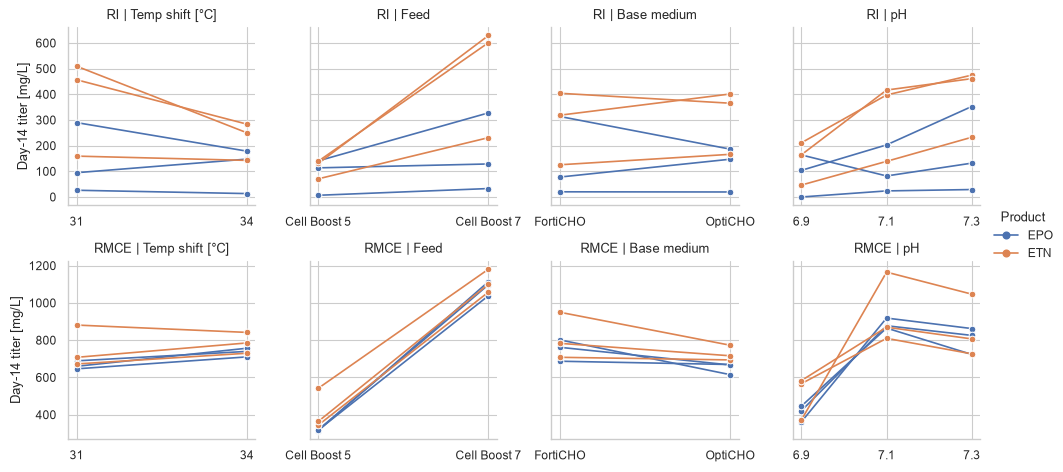

In [4]:
# mean titer per clone at each factor level, averaged over the other conditions
d14_factors = (d14.melt(id_vars=["integration", "product", "clone", "value"], value_vars=FACTORS, var_name="factor", value_name="level").groupby(["integration", "product", "clone", "factor", "level"], as_index=False).value.mean())

fig2_labels = {**FACTOR_LABELS, "temp_shift": "Temp shift [°C]"}
fig2 = sns.relplot(d14_factors.replace({"factor": fig2_labels}).rename(columns={"product": "Product"}), kind="line", x="level", y="value", hue="Product", units="clone", estimator=None, marker="o", row="integration", col="factor", col_order=[fig2_labels[f] for f in FACTORS], height=2.5, facet_kws={"sharex": False, "sharey": "row"})
fig2.set_titles("{row_name} | {col_name}").set_xlabels("").set_ylabels("Day-14 titer [mg/L]")
fig2.savefig(OUT / "fig_clone_profiles")
plt.show()

In [5]:
def anova_func(d):
    """y ~ process factors + product + clone.
    F and p: Type II, against the residual"""
    d = d.assign(clone_nr=d.groupby("product").clone.rank(method="dense"))
    fit = smf.ols("y ~ C(temp_shift) + C(feed) + C(medium) + C(ph) + C(product) + C(clone_nr)", d).fit()
    a = sm.stats.anova_lm(fit, typ=2).rename(columns={"PR(>F)": "p"})
    a.index = [*FACTORS, "product", "clone", "residual"]
    a["logworth"] = -np.log10(a.p)
    return a.rename_axis("term")

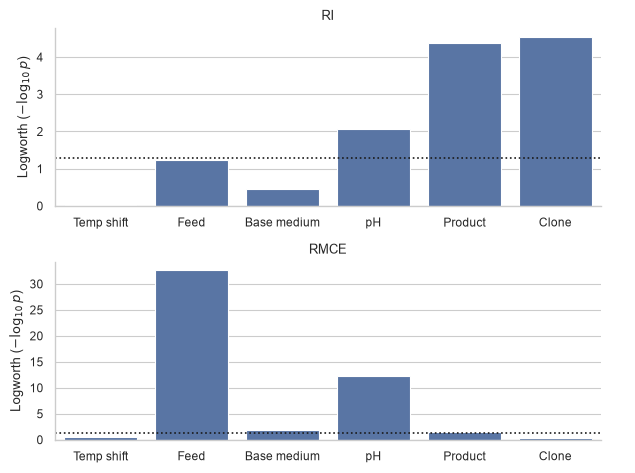

In [6]:
d14['y'] = np.log1p(d14.value)

anova_by_integration = {i: anova_func(d) for i, d in d14.groupby("integration")}
factor_importance = pd.concat(anova_by_integration, names=["integration"]).reset_index()
factor_importance.to_csv(OUT / "factor_importance_day14.csv", index=False)

fig3 = sns.catplot(factor_importance[factor_importance.term != "residual"].replace({"term": {**FACTOR_LABELS, "product": "Product", "clone": "Clone"}}), kind="bar", x="term", y="logworth", row="integration", height=2.5, aspect=2.5, sharey=False, sharex=False)
fig3.refline(y=-np.log10(0.05), color="k", linestyle=":")
fig3.set_titles("{row_name}").set_xlabels("").set_ylabels(LOGWORTH)
fig3.savefig(OUT / "fig_factor_importance")
plt.show()

In [7]:
factor_importance

,integration,term,sum_sq,df,F,p,logworth
0,RI,temp_shift,0.004609,1.0,0.003307,9.544365e-01,0.020253
1,RI,feed,5.343121,1.0,3.833940,5.740613e-02,1.241042
2,RI,medium,1.254254,1.0,0.899986,3.486273e-01,0.457639
3,RI,ph,15.005581,2.0,5.383604,8.617198e-03,2.064634
4,RI,product,29.682138,1.0,21.298324,4.185413e-05,4.378262
5,RI,clone,38.623089,2.0,13.856938,2.841479e-05,4.546455
6,RI,residual,54.351852,39.0,NaN,NaN,NaN
7,RMCE,temp_shift,0.185412,1.0,1.252539,2.650703e-01,0.576639
8,RMCE,feed,38.768244,1.0,261.896401,2.533622e-33,32.596258
9,RMCE,medium,0.955150,1.0,6.452456,1.222088e-02,1.912898


## Clone variance component of day-14 titer

A **linear mixed model** treats the clones as a
random sample of the clones one could have picked, and estimates how much titer varies between such
clones (**clone variance**) compared with vessel-to-vessel noise (**residual variance**), after removing
the effects of the process factors and the product.

**ICC** (intraclass correlation) = clone variance / (clone variance + residual variance): the fraction of
the remaining variation that is due to the clone. 0 = clone choice is irrelevant; 1 = everything left is
clone. A p-value tests whether the clone variance is larger than zero.

Technical note: variance components by REML; p from a likelihood-ratio test (ML fits) against the 50:50
mixture of χ²₀ and χ²₁.

In [8]:
def clone_icc(d, formula, reml, method=None):
    """Clone random-intercept variance and ICC. p: likelihood-ratio test (ML fits) against the 50:50 χ²₀/χ²₁ mixture."""
    fit = smf.mixedlm(formula, d, groups="clone").fit(reml=reml, method=method)
    ml = smf.mixedlm(formula, d, groups="clone").fit(reml=False, method=method) if reml else fit
    lr = max(0, 2 * (ml.llf - smf.ols(formula, d).fit().llf))
    vc = fit.cov_re.iloc[0, 0]
    p = 1.0 if lr == 0 else stats.chi2.sf(lr, 1) / 2
    return dict(n_vessels=len(d), n_clones=d.clone.nunique(), clone_variance=vc, residual_variance=fit.scale,
                ICC=vc / (vc + fit.scale), LR=lr, p=p, logworth=-np.log10(p) + 0.0, converged=fit.converged)

In [9]:
clone_icc_day14 = pd.DataFrame({
    i: clone_icc(d, "y ~ C(temp_shift) + C(feed) + C(medium) + C(ph) + C(product)", reml=True)
    for i, d in d14.groupby("integration")
}).T.rename_axis("integration").reset_index()
clone_icc_day14.to_csv(OUT / "clone_icc_day14.csv", index=False)
clone_icc_day14

/home/laeb/.pyenv/versions/3.14.7/envs/scipy/lib/python3.14/site-packages/statsmodels/regression/mixed_linear_model.py:2384: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  rslt = super().fit(
/tmp/ipykernel_154656/1489706428.py:3: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  fit = smf.mixedlm(formula, d, groups="clone").fit(reml=reml, method=method)
/tmp/ipykernel_154656/1489706428.py:3: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  fit = smf.mixedlm(formula, d, groups="clone").fit(reml=reml, method=method)
/home/laeb/.pyenv/versions/3.14.7/envs/scipy/lib/python3.14/site-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
/home/laeb/.pyenv/versions/3.14.7/envs/scipy/lib/python3.14/site-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.sco

,integration,n_vessels,n_clones,clone_variance,residual_variance,ICC,LR,p,logworth,converged
0,RI,48,6,1.47338,1.117599,0.568658,19.475189,0.000005,5.292792,True
1,RMCE,143,6,0.000367,0.147142,0.002487,0,1.0,0.0,True


## Clone-to-clone variance during the culture

**Setup.** Take one product and one of the 8 conditions that both RI and RMCE clones were grown in. That
gives three RI vessels and three RMCE vessels (one per clone) grown under identical conditions. On each
culture day, compute how much the three clones differ from each other (the **variance** across clones)
for RI and for RMCE. 2 products × 8 conditions = 16 such matched comparisons per day

**Panel a: how big is the difference?** For each matched comparison, the ratio RI variance / RMCE
variance is expressed as log2: 0 = equally variable, +1 = RI clones twice as variable, +3 = 8×, −1 = RMCE
twice as variable. The line is the median of the 16 comparisons. The shaded band is a **bootstrap 95 %
confidence interval**: the range in which the median would fall if the experiment were repeated
(estimated by resampling the 16 comparisons 1000 times). Where the band stays above 0, RI clones are
reliably more variable.

**Panel b: is it consistent, or driven by a few conditions?** The **Wilcoxon signed-rank test** asks
whether the 16 log2 ratios lean to one side of 0 more than chance allows. It ranks the ratios by size,
so a single extreme condition cannot drive the result. The result is plotted as logworth (evidence
strength), **with the sign of the effect**: points above the upper dotted line mean RMCE clones are
consistently *less* variable (p < 0.05); points below the lower dotted line mean consistently *more*
variable; between the lines there is no consistent difference.

In [10]:
# log(x+1) trajectories per vessel, linearly interpolated to integer culture days within the sampled range,
# restricted to the product x condition cells grown with both RI and RMCE clones
def interp_daily(g):
    days = np.arange(np.ceil(g.day.min()), np.floor(g.day.max()) + 1).astype(int)
    return pd.DataFrame({"day": days, "y": np.interp(days, g.day, np.log1p(g.value))})

keys = ["parameter", "vessel", "product", "integration", "clone", "condition", "run"]
daily = ambr[ambr.parameter.isin(["CELL_COUNT", "AMMONIUM", "LACTATE", "titer"])].sort_values("day").groupby(keys).apply(interp_daily).reset_index(keys)
daily = daily[daily.groupby(["product", "condition"]).integration.transform("nunique") == 2]

clone_var = daily.groupby(["parameter", "day", "product", "condition", "integration"]).y.var().unstack().dropna()
variance_cells = np.log2((clone_var.RI + 1e-8) / (clone_var.RMCE + 1e-8)).rename("log2_ratio").reset_index()
clone_variance = variance_cells.groupby(["parameter", "day"]).log2_ratio.agg(
    n_cells="size", n_RMCE_lower=lambda x: (x > 0).sum(), median_log2_ratio="median",
    wilcoxon_p=lambda x: stats.wilcoxon(x).pvalue).reset_index()
clone_variance["signed_logworth"] = np.sign(clone_variance.median_log2_ratio) * -np.log10(clone_variance.wilcoxon_p)
clone_variance.to_csv(OUT / "clone_variance_by_day.csv", index=False)

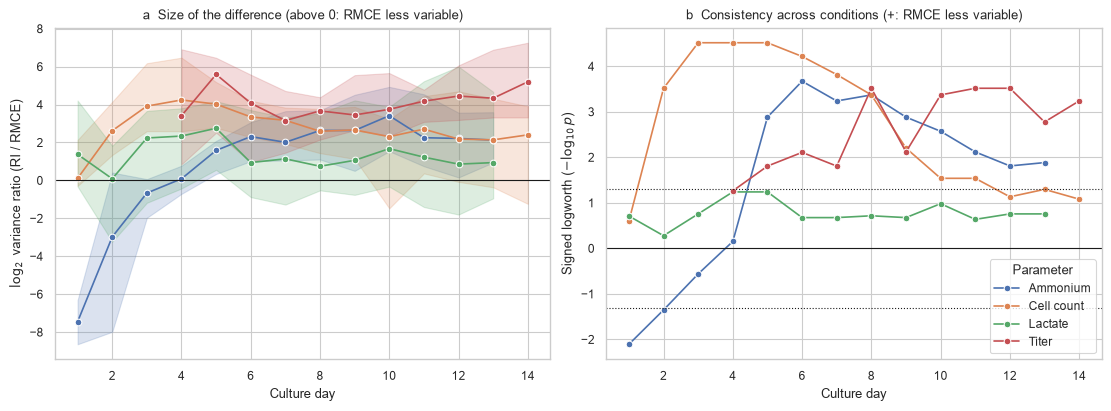

In [11]:
fig5, axs = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")

fig5_names = {"parameter": PARAMETER_LABELS}
sns.lineplot(variance_cells.replace(fig5_names), x="day", y="log2_ratio", hue="parameter", estimator="median", errorbar=("ci", 95),
             marker="o", legend=False, ax=axs[0])
sns.lineplot(clone_variance.replace(fig5_names).rename(columns={"parameter": "Parameter"}), x="day", y="signed_logworth", hue="Parameter", marker="o", ax=axs[1])
axs[0].set(xlabel="Culture day", ylabel=r"$\log_2$ variance ratio (RI / RMCE)")
axs[1].set(xlabel="Culture day", ylabel="Signed l" + LOGWORTH[1:])
axs[0].set(title="a  Size of the difference (above 0: RMCE less variable)")
axs[1].set(title="b  Consistency across conditions (+: RMCE less variable)")
for ax, ys in zip(axs, [[0], [0, -np.log10(0.05), np.log10(0.05)]]):
    for yline in ys:
        ax.axhline(yline, ls="-" if yline == 0 else ":", c="k", lw=0.8)
fig5.savefig(OUT / "fig_clone_variance_by_day")
plt.show()

## Clone variance component per culture day

The mixed model applied to every culture day, on the 8 conditions shared by RI and RMCE.
For each day it estimates how much of the variation is due to the clone after removing product and
process condition.

**Top: ICC**, the fraction of the variation due to clone (0 = clone choice irrelevant, 1 = clone is
everything). **Bottom:** evidence that the clone effect is real, as logworth; above the dotted line =
p < 0.05.

**What you should see.** For VCD and titer the RI line is high: a large share of the
differences between vessels comes from which RI clone is in the vessel. The RMCE line stays low:
ICC ≤ 0.26 for VCD on all days; for titer ≤ 0.35, and below 0.06 from day 11 to the harvest on day 14. Ammonium and lactate are mixed: early RMCE values are high because each RMCE clone had its own
run, so run-to-run differences count as clone differences, and later both methods show modest clone effects.

Fitted when ≥ 8 vessels and ≥ 3 clones are available. EPO RI titers were sampled from day 8 on, so RI
titer on days 4 to 7 is ETN only. Technical note: variance components by REML; likelihood-ratio test (ML fits) against the 50:50 χ²₀/χ²₁
mixture.

In [12]:
def fit_day(d):
    if len(d) >= 8 and d.clone.nunique() >= 3:
        formula = "y ~ C(product) + C(condition)" if d["product"].nunique() > 1 else "y ~ C(condition)"
        # lbfgs reaches the highest likelihood; fall back when it fails or does not converge
        for method in ["lbfgs", "powell", "nm"]:
            try:
                res = pd.Series(clone_icc(d, formula, reml=True, method=method))
                if res.converged:
                    break
            except np.linalg.LinAlgError:
                pass
        return res

clone_icc_daily = daily.groupby(["parameter", "day", "integration"]).apply(fit_day).reset_index()
clone_icc_daily.to_csv(OUT / "clone_icc_by_day.csv", index=False)

/home/laeb/.pyenv/versions/3.14.7/envs/scipy/lib/python3.14/site-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
/tmp/ipykernel_154656/1489706428.py:3: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  fit = smf.mixedlm(formula, d, groups="clone").fit(reml=reml, method=method)
/tmp/ipykernel_154656/1489706428.py:3: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  fit = smf.mixedlm(formula, d, groups="clone").fit(reml=reml, method=method)
/tmp/ipykernel_154656/1489706428.py:4: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  ml = smf.mixedlm(formula, d, groups="clone").fit(reml=False, method=method) if reml else fit
/tmp/ipykernel_154656/1489706428.py:4: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  ml = smf.mixedlm(formula, d, group

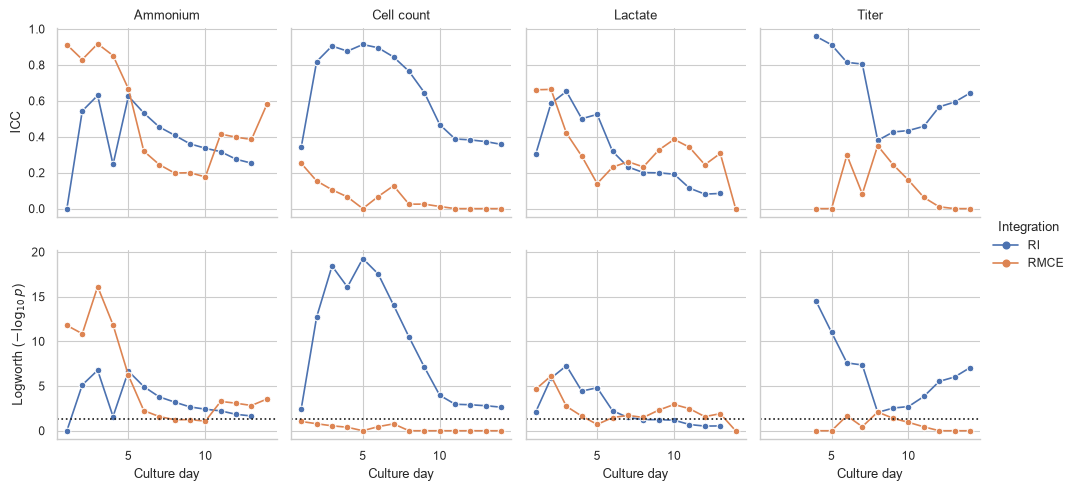

In [13]:
fig6 = sns.relplot(clone_icc_daily.melt(id_vars=["parameter", "day", "integration"], value_vars=["ICC", "logworth"])
                   .replace({"parameter": PARAMETER_LABELS}).rename(columns={"integration": "Integration"}),
                   kind="line", x="day", y="value", hue="Integration", row="variable", col="parameter",
                   marker="o", height=2.5, facet_kws={"sharey": "row"})
label_grid(fig6, ["ICC", LOGWORTH])
for ax in fig6.axes[1]:
    ax.axhline(-np.log10(0.05), ls=":", c="k")
fig6.savefig(OUT / "fig_clone_icc_by_day")
plt.show()